In [1]:
# ==================================================
# FRAUD RISK INTELLIGENCE PIPELINE
# Section A: Data Forensics & Quality Engineering
# ==================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries imported successfully!")
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)

Libraries imported successfully!
Pandas Version: 3.1.0
NumPy Version: 2.4.6


In [2]:
# ==================================================
# Load Raw Dataset
# ==================================================

# Find project root
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = current_dir

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "transaction_fraud_risk_advanced_dataset.csv"
)

print("Dataset Path:", DATA_PATH)

# Load dataset
df = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully!")

print("\nDataset Shape:", df.shape)

display(df.head())

Dataset Path: e:\fraud-risk-intelligence\fraud-risk-intelligence\data\raw\transaction_fraud_risk_advanced_dataset.csv

Dataset loaded successfully!

Dataset Shape: (3000, 25)


,transaction_id,hour,day_of_week,transaction_amount,distance_from_usual_location_km,transactions_last_1h,transactions_last_24h,account_age_days,failed_logins_24h,prior_chargebacks,...,card_presence,channel,country,device_type,merchant_category,authentication_level,new_device,billing_address_mismatch,customer_tier,fraud
0,TXN5000001,20,0,35.01,47.93,6,12,783,0,0,...,Not present,E-commerce,Sri Lanka,iOS,Grocery,Standard,0,1,Basic,1
1,TXN5000002,4,1,29.66,78.02,2,6,564,0,0,...,Not present,POS,UK,macOS,Grocery,Strong,0,1,Basic,0
2,TXN5000003,0,4,46.05,21.39,5,10,1618,0,0,...,Present,E-commerce,Sri Lanka,Android,Grocery,Standard,0,0,Gold,0
3,TXN5000004,15,4,77.02,95.29,4,10,1433,1,0,...,Present,E-commerce,Sri Lanka,Other,Grocery,Strong,0,0,Basic,0
4,TXN5000005,8,3,187.65,6.08,1,10,50,0,0,...,Not present,POS,Sri Lanka,Android,Grocery,Standard,0,0,Basic,0


In [3]:
# ==================================================
# Initial Dataset Inspection
# ==================================================

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("\nTotal Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
print(df["fraud"].value_counts())

print("\nTarget Percentage:")
print(df["fraud"].value_counts(normalize=True) * 100)

DATASET OVERVIEW

Total Rows: 3000
Total Columns: 25

Column Names:
['transaction_id', 'hour', 'day_of_week', 'transaction_amount', 'distance_from_usual_location_km', 'transactions_last_1h', 'transactions_last_24h', 'account_age_days', 'failed_logins_24h', 'prior_chargebacks', 'device_age_days', 'merchant_risk_score', 'ip_risk_score', 'email_age_days', 'login_to_transaction_minutes', 'card_presence', 'channel', 'country', 'device_type', 'merchant_category', 'authentication_level', 'new_device', 'billing_address_mismatch', 'customer_tier', 'fraud']

Data Types:
transaction_id                         str
hour                                 int64
day_of_week                          int64
transaction_amount                 float64
distance_from_usual_location_km    float64
transactions_last_1h                 int64
transactions_last_24h                int64
account_age_days                     int64
failed_logins_24h                    int64
prior_chargebacks                    int64
dev

In [4]:
# ============================================================
# SECTION A - DATA FORENSICS & QUALITY ENGINEERING
# Cell 04: Comprehensive Data Quality Summary
# ============================================================

quality_report = pd.DataFrame({
    "column": df.columns,
    "data_type": df.dtypes.astype(str).values,
    "missing_count": df.isnull().sum().values,
    "missing_percentage": (
        df.isnull().mean() * 100
    ).round(2).values,
    "unique_values": df.nunique(dropna=True).values
})

quality_report = quality_report.sort_values(
    by="missing_percentage",
    ascending=False
).reset_index(drop=True)

print("=" * 65)
print("DATA QUALITY SUMMARY")
print("=" * 65)

print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print(f"Total Missing Values: {df.isnull().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")
print(f"Duplicate Transaction IDs: {df['transaction_id'].duplicated().sum()}")

display(quality_report)

print("\nColumns containing missing values:")

display(
    quality_report[
        quality_report["missing_count"] > 0
    ]
)

DATA QUALITY SUMMARY
Total Rows: 3000
Total Columns: 25
Total Missing Values: 582
Duplicate Rows: 0
Duplicate Transaction IDs: 0


,column,data_type,missing_count,missing_percentage,unique_values
0,authentication_level,str,289,9.63,2
1,distance_from_usual_location_km,float64,75,2.50,2402
2,merchant_risk_score,float64,60,2.00,658
3,login_to_transaction_minutes,float64,60,2.00,1945
4,transaction_amount,float64,53,1.77,2779
5,ip_risk_score,float64,45,1.50,574
6,transaction_id,str,0,0.00,3000
7,day_of_week,int64,0,0.00,7
8,hour,int64,0,0.00,24
9,failed_logins_24h,int64,0,0.00,4



Columns containing missing values:


,column,data_type,missing_count,missing_percentage,unique_values
0,authentication_level,str,289,9.63,2
1,distance_from_usual_location_km,float64,75,2.50,2402
2,merchant_risk_score,float64,60,2.00,658
3,login_to_transaction_minutes,float64,60,2.00,1945
4,transaction_amount,float64,53,1.77,2779
5,ip_risk_score,float64,45,1.50,574


In [5]:
# ============================================================
# Cell 05: Invalid and Impossible Values Detection
# ============================================================

invalid_checks = {
    "Invalid hour": ~df["hour"].between(0, 23),

    "Invalid day of week": ~df["day_of_week"].between(0, 6),

    "Invalid transaction amount": (
        df["transaction_amount"] <= 0
    ),

    "Negative distance": (
        df["distance_from_usual_location_km"] < 0
    ),

    "Negative account age": (
        df["account_age_days"] < 0
    ),

    "Negative device age": (
        df["device_age_days"] < 0
    ),

    "Negative email age": (
        df["email_age_days"] < 0
    ),

    "Invalid merchant risk score": (
        df["merchant_risk_score"].notna()
        & ~df["merchant_risk_score"].between(0, 1)
    ),

    "Invalid IP risk score": (
        df["ip_risk_score"].notna()
        & ~df["ip_risk_score"].between(0, 1)
    ),

    "Invalid fraud label": (
        ~df["fraud"].isin([0, 1])
    ),

    "Invalid new device indicator": (
        ~df["new_device"].isin([0, 1])
    ),

    "Invalid billing mismatch indicator": (
        ~df["billing_address_mismatch"].isin([0, 1])
    ),

    "Invalid transaction velocity": (
        df["transactions_last_1h"]
        > df["transactions_last_24h"]
    ),

    "Negative login duration": (
        df["login_to_transaction_minutes"] < 0
    )
}

invalid_report = pd.DataFrame({
    "validation_check": list(invalid_checks.keys()),
    "invalid_count": [
        int(condition.sum())
        for condition in invalid_checks.values()
    ]
})

invalid_report["status"] = np.where(
    invalid_report["invalid_count"] == 0,
    "PASS",
    "REVIEW"
)

print("=" * 65)
print("DATA VALIDATION REPORT")
print("=" * 65)

display(invalid_report)

print(
    "\nTotal Failed Checks:",
    (invalid_report["status"] == "REVIEW").sum()
)

DATA VALIDATION REPORT


,validation_check,invalid_count,status
0,Invalid hour,0,PASS
1,Invalid day of week,0,PASS
2,Invalid transaction amount,0,PASS
3,Negative distance,0,PASS
4,Negative account age,0,PASS
5,Negative device age,0,PASS
6,Negative email age,0,PASS
7,Invalid merchant risk score,0,PASS
8,Invalid IP risk score,0,PASS
9,Invalid fraud label,0,PASS



Total Failed Checks: 0


In [6]:
# ============================================================
# Cell 06: Missingness vs Fraud Analysis
# ============================================================

missing_columns = df.columns[
    df.isnull().any()
].tolist()

missingness_results = []

for col in missing_columns:

    missing_mask = df[col].isnull()

    missing_fraud_rate = df.loc[
        missing_mask, "fraud"
    ].mean() * 100

    present_fraud_rate = df.loc[
        ~missing_mask, "fraud"
    ].mean() * 100

    missingness_results.append({
        "feature": col,
        "missing_count": missing_mask.sum(),
        "missing_fraud_rate": round(missing_fraud_rate, 2),
        "present_fraud_rate": round(present_fraud_rate, 2),
        "fraud_rate_difference": round(
            missing_fraud_rate - present_fraud_rate, 2
        )
    })

missingness_df = pd.DataFrame(
    missingness_results
)

missingness_df = missingness_df.sort_values(
    "fraud_rate_difference",
    ascending=False
)

print("=" * 65)
print("MISSINGNESS AND FRAUD RELATIONSHIP")
print("=" * 65)

display(missingness_df)

MISSINGNESS AND FRAUD RELATIONSHIP


,feature,missing_count,missing_fraud_rate,present_fraud_rate,fraud_rate_difference
5,authentication_level,289,19.03,11.40,7.63
4,login_to_transaction_minutes,60,11.67,12.14,-0.48
3,ip_risk_score,45,11.11,12.15,-1.04
0,transaction_amount,53,9.43,12.18,-2.75
1,distance_from_usual_location_km,75,5.33,12.31,-6.97
2,merchant_risk_score,60,3.33,12.31,-8.98


In [7]:
# ============================================================
# SECTION A - DATA FORENSICS
# Cell 07: Outlier Detection and Extreme Value Analysis
# ============================================================

outlier_features = [
    "transaction_amount",
    "distance_from_usual_location_km",
    "transactions_last_1h",
    "transactions_last_24h",
    "login_to_transaction_minutes",
    "merchant_risk_score",
    "ip_risk_score"
]

outlier_results = []

for col in outlier_features:

    valid_data = df[[col, "fraud"]].dropna(subset=[col])

    Q1 = valid_data[col].quantile(0.25)
    Q3 = valid_data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (valid_data[col] < lower_bound) |
        (valid_data[col] > upper_bound)
    )

    outlier_count = int(outlier_mask.sum())

    outlier_percentage = (
        outlier_count / len(valid_data)
    ) * 100

    if outlier_count > 0:
        outlier_fraud_rate = (
            valid_data.loc[outlier_mask, "fraud"].mean() * 100
        )
    else:
        outlier_fraud_rate = np.nan

    outlier_results.append({
        "feature": col,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "IQR": round(IQR, 2),
        "lower_bound": round(lower_bound, 2),
        "upper_bound": round(upper_bound, 2),
        "outlier_count": outlier_count,
        "outlier_percentage": round(outlier_percentage, 2),
        "outlier_fraud_rate": round(outlier_fraud_rate, 2),
        "maximum_value": round(valid_data[col].max(), 2)
    })

outlier_df = pd.DataFrame(outlier_results)

print("=" * 70)
print("OUTLIER DETECTION REPORT")
print("=" * 70)

display(outlier_df)

print("\nTotal outlier flags across selected features:")
print(outlier_df["outlier_count"].sum())

print("\nNote: Outlier flags may overlap across features.")
print("No observations have been removed.")

OUTLIER DETECTION REPORT


,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage,outlier_fraud_rate,maximum_value
0,transaction_amount,49.23,155.26,106.03,-109.81,314.30,206,6.99,24.27,5538.15
1,distance_from_usual_location_km,16.81,48.45,31.64,-30.65,95.91,87,2.97,22.99,1173.27
2,transactions_last_1h,1.00,3.00,2.00,-2.00,6.00,21,0.70,33.33,10.00
3,transactions_last_24h,6.00,9.00,3.00,1.50,13.50,88,2.93,11.36,113.00
4,login_to_transaction_minutes,6.92,21.72,14.80,-15.28,43.91,167,5.68,10.78,120.00
5,merchant_risk_score,0.18,0.41,0.22,-0.15,0.74,18,0.61,27.78,0.82
6,ip_risk_score,0.12,0.32,0.20,-0.18,0.61,36,1.22,22.22,0.74



Total outlier flags across selected features:
623

Note: Outlier flags may overlap across features.
No observations have been removed.


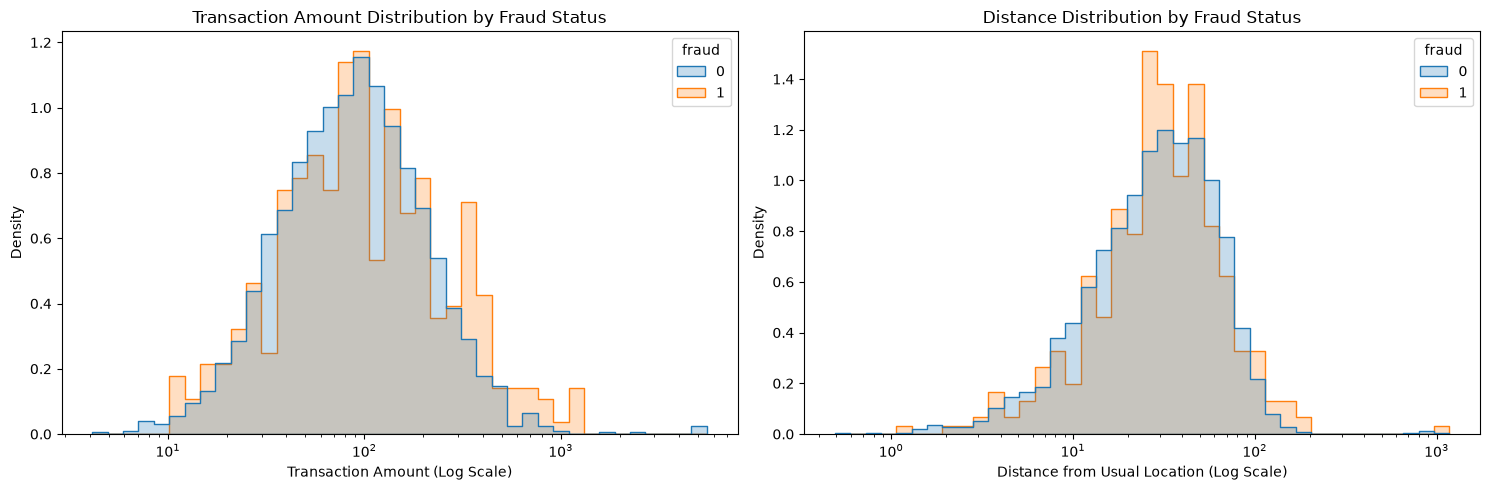

In [8]:
# ============================================================
# Cell 08: Transaction Distribution Analysis
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

# -----------------------------------------
# Plot 01: Transaction Amount Distribution
# -----------------------------------------

sns.histplot(
    data=df,
    x="transaction_amount",
    hue="fraud",
    bins=40,
    element="step",
    stat="density",
    common_norm=False,
    log_scale=True,
    ax=axes[0]
)

axes[0].set_title(
    "Transaction Amount Distribution by Fraud Status"
)

axes[0].set_xlabel(
    "Transaction Amount (Log Scale)"
)

axes[0].set_ylabel(
    "Density"
)

# -----------------------------------------
# Plot 02: Distance Distribution
# -----------------------------------------

sns.histplot(
    data=df,
    x="distance_from_usual_location_km",
    hue="fraud",
    bins=40,
    element="step",
    stat="density",
    common_norm=False,
    log_scale=True,
    ax=axes[1]
)

axes[1].set_title(
    "Distance Distribution by Fraud Status"
)

axes[1].set_xlabel(
    "Distance from Usual Location (Log Scale)"
)

axes[1].set_ylabel(
    "Density"
)

plt.tight_layout()
plt.show()

In [9]:
# ============================================================
# Cell 09: Data Leakage Investigation
# ============================================================

leakage_audit = [
    {
        "feature": "transaction_id",
        "risk": "Identifier / possible ordering proxy",
        "decision": "EXCLUDE",
        "reason": "Not a defensible fraud predictor"
    },
    {
        "feature": "fraud",
        "risk": "Target leakage",
        "decision": "TARGET ONLY",
        "reason": "Must never be included in model inputs"
    },
    {
        "feature": "prior_chargebacks",
        "risk": "Historical information leakage",
        "decision": "VERIFY",
        "reason": "Must include only chargebacks known before transaction"
    },
    {
        "feature": "merchant_risk_score",
        "risk": "Possible post-event information",
        "decision": "VERIFY",
        "reason": "Score must be available at prediction time"
    },
    {
        "feature": "ip_risk_score",
        "risk": "Possible post-event information",
        "decision": "VERIFY",
        "reason": "Score must be computed before authorization"
    },
    {
        "feature": "authentication_level",
        "risk": "Prediction-time availability",
        "decision": "VERIFY",
        "reason": "Must be known before the fraud decision"
    },
    {
        "feature": "distance_from_usual_location_km",
        "risk": "Historical profile leakage",
        "decision": "VERIFY",
        "reason": "Customer profile must use past observations only"
    },
    {
        "feature": "transactions_last_1h",
        "risk": "Future transaction leakage",
        "decision": "VERIFY",
        "reason": "Rolling count must not include future transactions"
    },
    {
        "feature": "transactions_last_24h",
        "risk": "Future transaction leakage",
        "decision": "VERIFY",
        "reason": "Rolling count must not include future transactions"
    }
]

leakage_df = pd.DataFrame(leakage_audit)

print("=" * 70)
print("DATA LEAKAGE AUDIT")
print("=" * 70)

display(leakage_df)

print("\nLeakage Audit Summary:")

display(
    leakage_df["decision"].value_counts()
)

# -----------------------------------------
# Identify excluded model columns
# -----------------------------------------

excluded_columns = [
    "transaction_id",
    "fraud"
]

candidate_feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

print("\nCandidate Feature Count:")
print(len(candidate_feature_columns))

print("\nExcluded Columns:")
print(excluded_columns)

print("\nCandidate Features:")
print(candidate_feature_columns)

print(
    "\nIMPORTANT: VERIFY fields require"
    " prediction-time availability checks."
)

DATA LEAKAGE AUDIT


,feature,risk,decision,reason
0,transaction_id,Identifier / possible ordering proxy,EXCLUDE,Not a defensible fraud predictor
1,fraud,Target leakage,TARGET ONLY,Must never be included in model inputs
2,prior_chargebacks,Historical information leakage,VERIFY,Must include only chargebacks known before tra...
3,merchant_risk_score,Possible post-event information,VERIFY,Score must be available at prediction time
4,ip_risk_score,Possible post-event information,VERIFY,Score must be computed before authorization
5,authentication_level,Prediction-time availability,VERIFY,Must be known before the fraud decision
6,distance_from_usual_location_km,Historical profile leakage,VERIFY,Customer profile must use past observations only
7,transactions_last_1h,Future transaction leakage,VERIFY,Rolling count must not include future transact...
8,transactions_last_24h,Future transaction leakage,VERIFY,Rolling count must not include future transact...



Leakage Audit Summary:


decision
VERIFY         7
EXCLUDE        1
TARGET ONLY    1
Name: count, dtype: int64


Candidate Feature Count:
23

Excluded Columns:
['transaction_id', 'fraud']

Candidate Features:
['hour', 'day_of_week', 'transaction_amount', 'distance_from_usual_location_km', 'transactions_last_1h', 'transactions_last_24h', 'account_age_days', 'failed_logins_24h', 'prior_chargebacks', 'device_age_days', 'merchant_risk_score', 'ip_risk_score', 'email_age_days', 'login_to_transaction_minutes', 'card_presence', 'channel', 'country', 'device_type', 'merchant_category', 'authentication_level', 'new_device', 'billing_address_mismatch', 'customer_tier']

IMPORTANT: VERIFY fields require prediction-time availability checks.


In [10]:
# ============================================================
# SECTION A - DATA FORENSICS
# Cell 10: Final Data Quality Investigation
# ============================================================

print("=" * 70)
print("FINAL DATA QUALITY INVESTIGATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Identify unique transactions containing IQR outliers
# ------------------------------------------------------------

outlier_flags = pd.DataFrame(index=df.index)

for col in outlier_features:

    valid = df[col].dropna()

    q1 = valid.quantile(0.25)
    q3 = valid.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_flags[col] = (
        (df[col] < lower) |
        (df[col] > upper)
    )

any_outlier = outlier_flags.any(axis=1)

unique_outlier_count = int(any_outlier.sum())

print("\nUnique Transactions With Outliers:")
print(unique_outlier_count)

print("\nPercentage of Transactions With Outliers:")
print(round(any_outlier.mean() * 100, 2))

# ------------------------------------------------------------
# 2. Compare fraud rates
# ------------------------------------------------------------

outlier_comparison = (
    df.assign(has_iqr_outlier=any_outlier)
    .groupby("has_iqr_outlier")["fraud"]
    .agg(
        transaction_count="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

outlier_comparison["fraud_rate"] = (
    outlier_comparison["fraud_rate"] * 100
).round(2)

print("\nFraud Rate Comparison:")

display(outlier_comparison)

# ------------------------------------------------------------
# 3. Categorical feature audit
# ------------------------------------------------------------

categorical_columns = [
    col
    for col in df.select_dtypes(
        include=["object", "string", "category"]
    ).columns
    if col != "transaction_id"
]

categorical_audit = pd.DataFrame({
    "feature": categorical_columns,
    "unique_categories": [
        df[col].nunique(dropna=True)
        for col in categorical_columns
    ],
    "missing_count": [
        df[col].isnull().sum()
        for col in categorical_columns
    ]
})

print("\nCategorical Feature Audit:")

display(categorical_audit)

# ------------------------------------------------------------
# 4. Missing data at transaction level
# ------------------------------------------------------------

transactions_with_missing = (
    df.isnull().any(axis=1).sum()
)

print("\nTransactions With At Least One Missing Value:")
print(transactions_with_missing)

print("\nTransactions Without Missing Values:")
print(len(df) - transactions_with_missing)

print("\nFinal Audit Completed Successfully!")

FINAL DATA QUALITY INVESTIGATION

Unique Transactions With Outliers:
565

Percentage of Transactions With Outliers:
18.83

Fraud Rate Comparison:


,has_iqr_outlier,transaction_count,fraud_count,fraud_rate
0,False,2435,260,10.68
1,True,565,104,18.41



Categorical Feature Audit:


,feature,unique_categories,missing_count
0,card_presence,2,0
1,channel,4,0
2,country,7,0
3,device_type,5,0
4,merchant_category,10,0
5,authentication_level,2,289
6,customer_tier,4,0



Transactions With At Least One Missing Value:
542

Transactions Without Missing Values:
2458

Final Audit Completed Successfully!


In [11]:
# ============================================================
# Cell 11: Generate Data Quality Report
# ============================================================

from pathlib import Path

REPORT_DIR = PROJECT_ROOT / "reports"

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

REPORT_PATH = (
    REPORT_DIR / "01_data_quality_report.md"
)

# ------------------------------------------------------------
# Helper: Convert DataFrame to Markdown table
# ------------------------------------------------------------

def dataframe_to_markdown_table(dataframe):

    columns = dataframe.columns.tolist()

    header = "| " + " | ".join(columns) + " |"

    separator = (
        "| " + " | ".join(["---"] * len(columns)) + " |"
    )

    rows = []

    for row in dataframe.itertuples(index=False, name=None):

        values = [
            str(value).replace("|", "\\|")
            for value in row
        ]

        rows.append(
            "| " + " | ".join(values) + " |"
        )

    return "\n".join(
        [header, separator] + rows
    )


# ------------------------------------------------------------
# Generate Report
# ------------------------------------------------------------

report = f"""
# Fraud Risk Intelligence - Data Quality Report

## 1. Dataset Overview

- Total transactions: {len(df)}
- Total columns: {df.shape[1]}
- Fraud transactions: {int(df['fraud'].sum())}
- Legitimate transactions: {int((df['fraud'] == 0).sum())}
- Overall fraud rate: {df['fraud'].mean() * 100:.2f}%
- Total missing cells: {int(df.isnull().sum().sum())}
- Transactions with missing values: {int(df.isnull().any(axis=1).sum())}
- Duplicate records: {int(df.duplicated().sum())}
- Duplicate transaction IDs: {int(df['transaction_id'].duplicated().sum())}

## 2. Missing Data Assessment

{dataframe_to_markdown_table(missingness_df)}

### Findings

Authentication-level missingness is associated with
a higher observed fraud rate.

Missingness may contain predictive information.
However, these relationships are observational
and require validation.

## 3. Invalid Value Assessment

{dataframe_to_markdown_table(invalid_report)}

### Findings

All implemented validation checks passed.

This does not guarantee that the dataset is free
from every possible data-quality issue.

## 4. Outlier Analysis

{dataframe_to_markdown_table(outlier_df)}

### Overall Outlier Comparison

{dataframe_to_markdown_table(outlier_comparison)}

### Findings

Outlier observations may contain useful fraud signals.

No observations have been removed.

The IQR method identifies statistical extremes,
not necessarily erroneous transactions.

## 5. Categorical Feature Audit

{dataframe_to_markdown_table(categorical_audit)}

## 6. Data Leakage Assessment

{dataframe_to_markdown_table(leakage_df)}

### Leakage Decisions

- Exclude transaction_id from predictive features.
- Use fraud only as the target variable.
- Verify point-in-time availability of historical
  and risk-related features before production use.

## 7. Data Treatment Decisions

### Missing Numerical Values

Planned treatment:
Median imputation fitted on training data only.

Missing indicators will be considered where useful.

### Missing Categorical Values

Planned treatment:
Explicit missing category where appropriate.

Authentication-level missingness will be
investigated as a predictive feature.

### Outliers

Planned treatment:
Retain valid extreme observations.

Investigate robust transformations and
model sensitivity to extreme values.

### Categorical Variables

Planned treatment:
Apply appropriate categorical encoding
within the preprocessing pipeline.

### Target Variable

Fraud is the classification target.

It must not appear in the model feature matrix.

### Transaction Identifier

Transaction ID will be excluded from training.

It may be retained separately for transaction
tracking and explanation outputs.

## 8. Validation Strategy

The available dataset does not contain
complete transaction timestamps or customer IDs.

Therefore, a genuine chronological or
customer-grouped split cannot be performed
using the available fields.

A stratified train/validation/test split is
planned, with its limitations documented.

All data-dependent preprocessing will be fitted
inside training or cross-validation pipelines.

The final test set will remain untouched until
the selected model and decision policy are frozen.

## 9. Conclusion

The dataset contains valid transaction records
under the implemented checks, but also includes
missing values and extreme observations.

These observations will be retained during
initial modeling.

Further feature validation, leakage review,
and robustness testing are required before
any production recommendation.
"""

REPORT_PATH.write_text(
    report.strip() + "\n",
    encoding="utf-8"
)

print("=" * 70)
print("DATA QUALITY REPORT GENERATED")
print("=" * 70)

print("Report Location:")
print(REPORT_PATH)

print("\nReport generated successfully!")

DATA QUALITY REPORT GENERATED
Report Location:
e:\fraud-risk-intelligence\fraud-risk-intelligence\reports\01_data_quality_report.md

Report generated successfully!
